#### Part 1: Understanding Product Categories

**Business Question:** What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

**1. Frequency Tables:**

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

**2. Visualizations:**

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

#### Part 2: Delving into Product Pricing

**Business Question:** How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

**Measures of Centrality:**

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

**Measures of Dispersion:**

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

**Visualizations:**

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved.
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

#### Part 3: Unpacking Product Ratings

**Business Question:** How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

**Measures of Centrality:**

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

**Measures of Dispersion:**

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

**Shape of the Distribution:**

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

**Visualizations:**

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pandas.core.dtypes import astype

%matplotlib inline

#### Loading dataset and initial exploration

In [2]:
df_amz = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df_amz.shape

(2443651, 9)

In [4]:
df_amz.head(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
5,6,B09B97WSLF,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
6,7,B09B9615X2,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
7,8,B01MTB55WH,Anker Soundcore 2 Portable Bluetooth Speaker w...,4.7,103673,39.99,False,0,Hi-Fi Speakers
8,9,B016MO90GW,"Bluetooth Speaker, Anker Soundcore Speaker Upg...",4.7,29909,29.99,False,0,Hi-Fi Speakers
9,10,B09ZQF5GZW,RIENOK Bluetooth Speaker Portable Wireless Blu...,4.5,16014,29.99,False,0,Hi-Fi Speakers


In [5]:
df_amz.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [6]:
df_amz.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [7]:
df_amz["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

#### Checked if the products with 0 stars were the same products that haven't been reviewd yet & Created new dataframe without the products that were rated 0 stars.

In [8]:
((df_amz['stars'] == 0) == (df_amz['reviews'] == 0)).all()

np.True_

In [9]:
df_rated = df_amz[df_amz['stars'] > 0]
df_rated["stars"].describe()

count    1.218010e+06
mean     4.319161e+00
std      5.552868e-01
min      1.000000e+00
25%      4.100000e+00
50%      4.400000e+00
75%      4.600000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [10]:
df_rated["category"].value_counts()

category
Sports & Outdoors                      143842
Beauty                                  19115
Hair Care                               18135
Skin Care                               17959
Women                                   17486
                                        ...  
Material Handling Products                 33
Motorbike Exhaust & Exhaust Systems        32
Lab & Scientific Products                  28
Boating Footwear                           19
Motorbike Drive & Gears                    19
Name: count, Length: 296, dtype: int64

In [11]:
top5 = df_rated['category'].value_counts().head(5)

#### Created categorical and numerical dataframes.

In [12]:
df_categorical = df_amz.select_dtypes(["string", "bool"])

In [13]:
df_numerical = df_amz.select_dtypes(["int64", "float64"])

In [14]:
df_numerical.isna().sum()

uid                  0
stars                0
reviews              0
price                0
boughtInLastMonth    0
dtype: int64

In [15]:
df_categorical.isna().sum()

asin            0
title           0
isBestSeller    0
category        0
dtype: int64

In [16]:
df_numerical.duplicated().sum()

np.int64(0)

In [17]:
df_categorical.duplicated().sum()

np.int64(0)

#### Part 1 - Frequency Table

In [18]:
df_categorical["category"].value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

#### Part 1 - Visualizations

In [19]:
vc_bar = df_categorical["category"].value_counts().reset_index().head(3)

<Axes: xlabel='category', ylabel='count'>

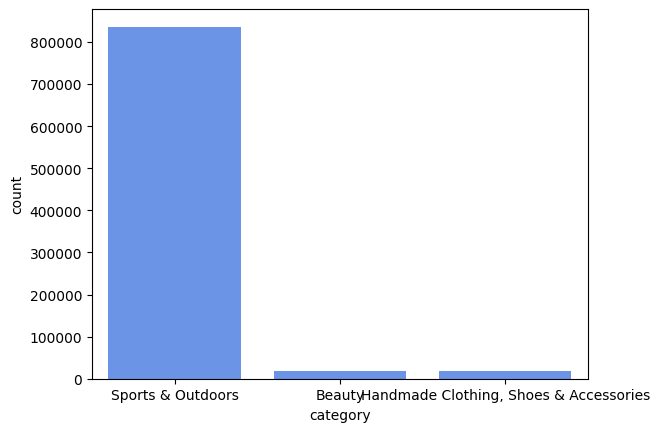

In [20]:
sns.barplot(data=vc_bar, x='category', y='count')

([<matplotlib.patches.Wedge at 0x13b30a7b0>,
 [Text(-0.5428530100728125, 0.956718667872059, 'Sports & Outdoors'),
  Text(-0.28411109894552133, -1.0626762834729908, 'Beauty'),
  Text(0.3031364057566328, -1.0574064117003217, 'Hair Care'),
  Text(0.7912768732700761, -0.7641210047027448, 'Skin Care'),
  Text(1.0647913888397162, -0.27607842772079877, 'Women')],
 [Text(-0.2961016418578977, 0.5218465461120321, '66.4%'),
  Text(-0.1549696903339207, -0.5796416091670858, '8.8%'),
  Text(0.1653471304127088, -0.5767671336547209, '8.4%'),
  Text(0.4316055672382233, -0.41679327529240623, '8.3%'),
  Text(0.5807953030034816, -0.15058823330225388, '8.1%')])

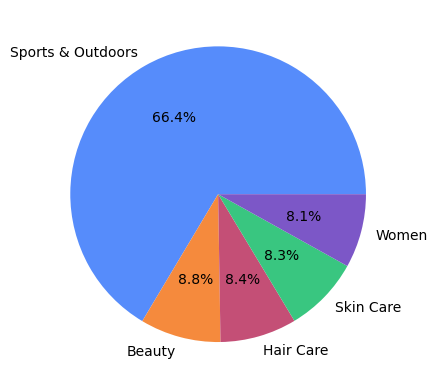

In [21]:
sizes = df_rated['category'].value_counts().head(5)

fig, ax = plt.subplots()
ax.pie(sizes, labels=sizes.index, autopct='%1.1f%%')

In [22]:
ct_bar = pd.crosstab(df_categorical["category"], df_categorical["isBestSeller"]).sort_values(by=True, ascending=False).reset_index().head(3)

<Axes: xlabel='category', ylabel='count'>

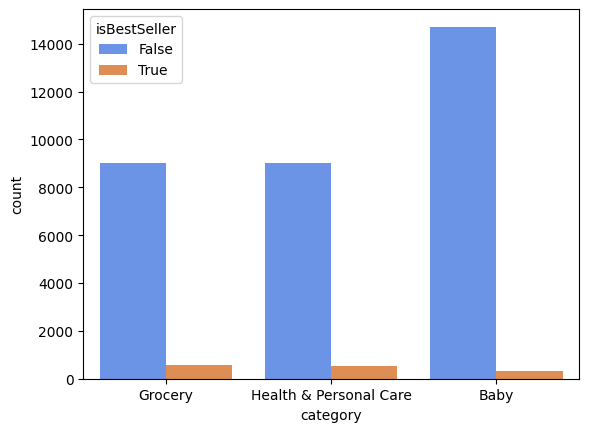

In [23]:
ct_bar_long = ct_bar.melt(id_vars='category', var_name='isBestSeller', value_name='count')
sns.barplot(data=ct_bar_long, x='category', y='count', hue='isBestSeller')

#### Part 2 - Measures of Centrality and Dispersion

In [24]:
pd.DataFrame({'mean': [df_numerical['price'].mean()]})

,mean
0,89.243809


In [25]:
pd.DataFrame({'median': [df_numerical['price'].median()]})

,median
0,19.09


In [26]:
df_numerical["price"].mode()

0    9.99
Name: price, dtype: float64

In [27]:
df_numerical["price"].std()

np.float64(345.60886175349873)

In [28]:
df_numerical["price"].var()

np.float64(119445.48532254901)

In [29]:
df_numerical['price'].max() - df_numerical['price'].min()

np.float64(100000.0)

In [30]:
df_numerical['price'].quantile(0.75) - df_numerical['price'].quantile(0.25)

np.float64(36.0)

#### Part 2 - Visualizations

<Axes: xlabel='price', ylabel='Count'>

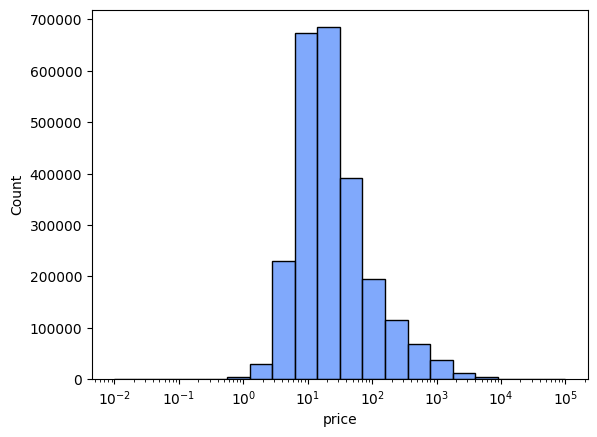

In [31]:
sns.histplot(data=df_numerical, x='price', bins=20, log_scale=True)

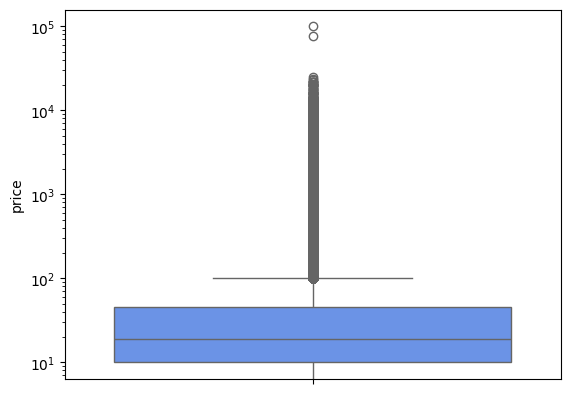

In [32]:
sns.boxplot(data=df_numerical, y='price')
plt.yscale('log')
plt.show()

#### Part 3 - Measures of Centrality, Dispersion and Shape of Distribution

In [33]:
pd.DataFrame({'mean': [df_rated['stars'].mean()]})

,mean
0,4.319161


In [34]:
pd.DataFrame({'median': [df_rated['stars'].median()]})

,median
0,4.4


In [35]:
df_rated["stars"].mode()

0    4.5
Name: stars, dtype: float64

In [36]:
df_rated["stars"].std()

np.float64(0.5552867504620729)

In [37]:
df_rated["stars"].var()

np.float64(0.3083433752387284)

In [38]:
df_rated["stars"].skew()

np.float64(-2.379568112212799)

In [39]:
df_rated["stars"].kurt()

np.float64(9.78193769066435)

In [40]:
df_rated['stars'].quantile(0.75) - df_rated['stars'].quantile(0.25)

np.float64(0.5)

#### Part 3 - Visualizations

<Axes: xlabel='stars', ylabel='Count'>

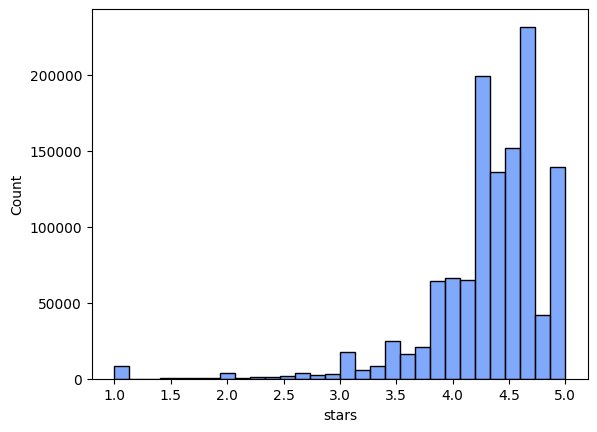

In [41]:
sns.histplot(data=df_rated, x='stars', bins=30)

# Findings: Amazon UK Product Listings — Univariate EDA

## Part 1 — Product Categories

Sports & Outdoors dominates the category column, but with caveats. A frequency analysis of the `category` column reveals that Sports & Outdoors accounts for 836,265 listings (34.2% of the entire dataset), while no other category exceeds 20,000 listings.

The scale of Sports & Outdoors's dominance is suspicious enough to warrant scrutiny. Several explanations are plausible:

- It is genuinely a mega-category covering an unusually broad product spectrum.
- It functions as a default or fallback bucket when sellers fail to specify a more specific category.

---

## Part 2 — Product Pricing

Prices are heavily right-skewed, with a small number of extreme outliers distorting summary statistics. The mean price (£89.24) is more than four times the median (£19.09), and the modal price is £9.99. The maximum recorded price is £100,000, while the 75th percentile is just £45.99.

The contrast between the IQR (£36) and the range (£100,000) makes the outlier problem unmistakable: the middle 50% of products sit in a narrow band, while a small minority of products are priced orders of magnitude higher.

---

## Part 3 — Product Ratings

Initial summary statistics on the `stars` column were misleading: the median and mode were both 0, and the mean was 2.15. However, an investigation revealed that the values `stars == 0` and `reviews == 0` describe exactly the same 1,225,641 products (verified by checking that the two boolean conditions are identical for every row). Since Amazon's rating scale starts at 1 (customers cannot leave a 0-star review) these values represent unrated products, not poorly-rated ones. They reflect missing data rather than negative customer sentiment.

For all subsequent ratings analysis, the dataset was filtered to products with at least one review (`stars > 0`), reducing the sample to 1,218,010 rated products.

The narrow IQR (0.5 stars) and small standard deviation (0.55) indicate that the middle 50% of rated products fall within just half a star of each other. This points to strong customer consensus that products on Amazon UK perform well overall.

---

## Cross-Cutting Observations

Two findings span multiple sections and deserve their own callout:

When the dataset is filtered to rated products only, Sports & Outdoors drops from 836,265 listings to 143,842. This means the category has an unusually high concentration of products that have never received a customer review. A plausible explanation is that Sports & Outdoors items tend to be higher-priced and infrequently purchased.

Any analysis that treats `stars == 0` as a rating will systematically underestimate customer satisfaction.

---

## Summary

The Amazon UK catalogue is dominated numerically by one very large category (Sports & Outdoors), priced with a strong right-skew driven by a small number of extreme outliers, and rated highly and tightly by customers, once the unrated half of the catalogue is correctly excluded from the analysis.

